In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import sklearn
import warnings
warnings.filterwarnings(
    "ignore",
    message="Unknown extension is not supported and will be removed",
    category=UserWarning
)
RANDOM_STATE = 42
DATA_PATH = Path('data/auth_events_lab01.xlsx')
df = pd.read_excel(DATA_PATH, sheet_name="Data")
print(sys.version)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)


3.12.2 (tags/v3.12.2:6abddd9, Feb  6 2024, 21:26:36) [MSC v.1937 64 bit (AMD64)]
pandas: 3.0.6
scikit-learn: 1.9.1


In [2]:
#СПИСКИ
tag_cols = [
    "user_id", "department", "auth_method",
    "failed_attempts_24h", "login_velocity_1h",
    "account_age_days", "password_age_days"
]

numeric_cols = [
    "hour",
    "failed_attempts_24h",
    "login_velocity_1h",
    "account_age_days",
    "password_age_days",
    "analyst_risk_score",
    "distance_from_usual_km"
]
categorical_cols = [
    "department",
    "country",
    "device_type",
    "os_family",
    "browser_family",
    "auth_method",
    "analyst_verdict",
    "user_id"
]
binary_cols = [
    "is_weekend",
"known_device",
"new_country",
"vpn_used",
"is_suspicious" ]


# 1. Постановка задачи

## 1.1. Прикладная задача ИБ

Требуется оценить каждую попытку аутентификации пользователя в информационной системе и определить, является ли она подозрительной. Результат может быть использован специалистом ИБ (оператором мониторинга) и системой управления событиями ИБ. На основе оценки можно принять решение: пропустить вход, потребовать дополнительный фактор аутентификации, временно заблокировать учётную запись или передать событие на ручную проверку. В данной работе анализируется профиль учётной записи и интенсивность входов (вариант 2).

## 1.2. Объект анализа и гранулярность

Объектом анализа является попытка аутентификации пользователя.
Гранулярность данных - одно событие попытки аутентификации. Каждая строка набора данных соответствует одной попытке аутентификации, а не пользователю или инциденту, так как один пользователь может выполнять множество попыток входа в разное время, а инцидент формируется на основе нескольких событий входа.

## 1.3. Целевая переменная

"is_suspicious" - целевая бинарная переменная:
- 0 - нормальное событие (Попытка аутентификации, которая не имеет признаки потенциально опасного поведения);
- 1 - подозрительное событие (Попытка аутентификации, которая имеет признаки потенциально опасного поведения).

## 1.4. Происхождение и ограничения данных

Используется синтетический набор данных `auth_events_lab01.xlsx`. Дата получения 28.09.2026. Исходный размер: 1430 строк, 23 колонки.
Возможные ограничения синтетических данных:
- наличие логических несоответствий в данных;
- возможное наличие дубликатов или некорректных форматов данных;
- искусственно сформированное распределение признаков, которое может отличаться от реального поведения пользователей.

## 1.5. Таблица признаков

In [3]:
# ОТКРЫТЬ КОД

def uniq(col):
    vals = sorted(
        df[col]
        .dropna().astype(str).loc[lambda x: x.str.lower() != "unknown"].unique()
    )
    return f"Конечный строковый набор ({len(vals)}): " + ", ".join(vals)

features_table = pd.DataFrame({
    "Название столбца": tag_cols,

    "Смысл": [
        "Псевдоним учетной записи пользователя",
        "Подразделение пользователя",
        "Способ аутентификации",
        "Количество неуспешных попыток входа за последние 24 часа",
        "Количество попыток входа за последний час",
        "Возраст учетной записи в днях",
        "Возраст текущего пароля в днях"
    ],

    "Фактический тип": [
        str(df[c].dtype) for c in tag_cols
    ],

    "Ожидаемый тип": [
        "Категориальный, строковый",
        "Категориальный, строковый",
        "Категориальный, строковый",
        "Целочисленный",
        "Целочисленный",
        "Целочисленный",
        "Целочисленный"
    ],

    "Допустимые значения": [
        "Непустая строка",
        uniq("department"),
        uniq("auth_method"),
        "Непустое целое значение ≥ 0",
        "Непустое целое значение ≥ 0",
       "Непустое целое значение ≥ 0",
        "Непустое целое значение ≥ 0 и ≤ account_age_days"
    ],

    "Момент доступности": [
        "Во время текущей попытки",
        "До текущей попытки",
        "Во время текущей попытки",
        "До текущей попытки",
        "До текущей попытки",
        "До текущей попытки",
        "До текущей попытки"
    ],

    "Решение об использовании": [
        "Использовать для группового разделения",
        "Использовать как признак",
        "Использовать как признак",
        "Использовать как признак",
        "Использовать как признак",
        "Использовать как признак",
        "Использовать как признак"
    ]
})

features_table.style \
    .set_properties(**{'text-align': 'center'}) \
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'center')]}
    ])

,Название столбца,Смысл,Фактический тип,Ожидаемый тип,Допустимые значения,Момент доступности,Решение об использовании
0,user_id,Псевдоним учетной записи пользователя,str,"Категориальный, строковый",Непустая строка,Во время текущей попытки,Использовать для группового разделения
1,department,Подразделение пользователя,str,"Категориальный, строковый","Конечный строковый набор (7): Finance, HR, IT, Operations, R&D, SOC, Sales",До текущей попытки,Использовать как признак
2,auth_method,Способ аутентификации,str,"Категориальный, строковый","Конечный строковый набор (4): fido2, otp, password, push",Во время текущей попытки,Использовать как признак
3,failed_attempts_24h,Количество неуспешных попыток входа за последние 24 часа,int64,Целочисленный,Непустое целое значение ≥ 0,До текущей попытки,Использовать как признак
4,login_velocity_1h,Количество попыток входа за последний час,int64,Целочисленный,Непустое целое значение ≥ 0,До текущей попытки,Использовать как признак
5,account_age_days,Возраст учетной записи в днях,int64,Целочисленный,Непустое целое значение ≥ 0,До текущей попытки,Использовать как признак
6,password_age_days,Возраст текущего пароля в днях,object,Целочисленный,Непустое целое значение ≥ 0 и ≤ account_age_days,До текущей попытки,Использовать как признак


# 2. Загрузка и первичная инвентаризация

In [4]:
# ОТКРЫТЬ КОД
initial_rows = df.shape[0]
initial_cols = df.shape[1]
print("=== Исходный размер датасета ===")
print("Количество строк:", initial_rows)
print("Количество столбцов:", initial_cols)
print("\n=== Первые 5 строк датасета ===")
display(df.head())
print("\n=== Последние 5 строк датасета ===")
display(df.tail())

print("\n=== Названия столбцов ===")
print(list(df.columns))
print("\n=== Типы данных и объем памяти ===")
df.info()
target = "is_suspicious"
print("\n=== Проверка целевого столбца ===")
target_count = df.columns.tolist().count(target)
print(f"Количество столбцов с названием '{target}':", target_count)
print("=== Описательная статистика числовых признаков ===")
print("Числовые столбцы:")
print(numeric_cols)
display(df[numeric_cols].describe())
print("=== Анализ категориальных признаков ===")
print("Категориальные столбцы:")
print(categorical_cols)
for col in categorical_cols:
    print("\n--- Столбец:", col, "---")
    print("Количество уникальных значений:", df[col].nunique())
    
    print("Наиболее частые категории:")
    display(df[col].value_counts().head())

=== Исходный размер датасета ===
Количество строк: 1430
Количество столбцов: 23

=== Первые 5 строк датасета ===


,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,hour,is_weekend,failed_attempts_24h,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
0,evt_001370,2026-03-12 20:27:57,usr_046,Operations,203.0.113.178,SE,mobile,Android,Chrome,password,20,0,0,1,39.4,871,229,0,0,0,benign,65,0
1,evt_000493,2026-01-06 00:17:20,usr_068,Sales,203.0.113.132,RU,mobile,Android,Chrome,password,0,0,0,5,16.9,2383,11,1,0,0,benign,43,0
2,evt_000433,2026-01-27 17:57:11,usr_033,SOC,192.0.2.185,PL,laptop,Windows,Chrome,password,17,0,2,5,28.8,795,258,1,0,0,benign,50,0
3,evt_001361,2026-03-10 16:30:25,usr_085,Sales,192.0.2.91,NO,mobile,Android,Chrome,otp,16,0,0,3,26.1,1186,184,1,0,0,benign,40,0
4,evt_000791,2026-02-10 05:26:56,usr_092,R&D,203.0.113.190,DE,laptop,Windows,Chrome,fido2,5,0,3,6,86.0,784,182,1,0,0,benign,7,0



=== Последние 5 строк датасета ===


,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,hour,is_weekend,failed_attempts_24h,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
1425,evt_000907,2026-03-09 00:01:20,usr_065,Operations,203.0.113.93,PL,tablet,iOS,Safari,push,0,0,0,2,49.8,3245,79,1,0,0,benign,15,0
1426,evt_001094,2026-01-17 09:15:30,usr_051,HR,192.0.2.165,RU,tablet,iOS,Safari,password,9,1,0,2,64.2,1803,239,1,0,0,benign,46,0
1427,evt_001253,2026-01-25 00:38:56,usr_061,R&D,198.51.100.128,RU,desktop,Windows,Chrome,otp,0,1,5,13,1088.3,2917,177,1,1,0,confirmed_threat,78,1
1428,evt_000743,2026-02-23 22:19:53,usr_043,HR,192.0.2.51,US,laptop,Windows,Edge,otp,22,0,1,5,14.4,1495,257,1,0,0,benign,31,0
1429,evt_000581,2026-02-14 19:29:43,usr_019,Finance,198.51.100.3,NL,laptop,Windows,Chrome,password,19,1,0,2,73.4,2915,unknown,1,0,0,benign,24,0



=== Названия столбцов ===
['event_id', 'timestamp', 'user_id', 'department', 'source_ip', 'country', 'device_type', 'os_family', 'browser_family', 'auth_method', 'hour', 'is_weekend', 'failed_attempts_24h', 'login_velocity_1h', 'distance_from_usual_km', 'account_age_days', 'password_age_days', 'known_device', 'new_country', 'vpn_used', 'analyst_verdict', 'analyst_risk_score', 'is_suspicious']

=== Типы данных и объем памяти ===
<class 'pandas.DataFrame'>
RangeIndex: 1430 entries, 0 to 1429
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   event_id                1430 non-null   str    
 1   timestamp               1430 non-null   str    
 2   user_id                 1430 non-null   str    
 3   department              1416 non-null   str    
 4   source_ip               1430 non-null   str    
 5   country                 1430 non-null   str    
 6   device_type             1430 non-null   st

...

auth_method
password    571
push        372
otp         330
fido2       157
Name: count, dtype: int64


--- Столбец: analyst_verdict ---
Количество уникальных значений: 2
Наиболее частые категории:


analyst_verdict
benign              1301
confirmed_threat     129
Name: count, dtype: int64


--- Столбец: user_id ---
Количество уникальных значений: 120
Наиболее частые категории:


user_id
usr_062    24
usr_025    21
usr_082    19
usr_060    17
usr_113    17
Name: count, dtype: int64

# 3. Проверка типов и допустимых значений

## 3.1. Поиск некорректных значений

In [5]:
# ОТКРЫТЬ КОД
# =============================================================================================

print("=== Проверка числовых признаков ===")

for col in numeric_cols:
    converted = pd.to_numeric(
        df[col],
        errors="coerce"
    )
    errors = df.loc[converted.isna(), col]
    if len(errors) > 0:
        print("\n---", col, "---")
        print("Фактический тип:", df[col].dtype)
        print("Количество значений, не являющихся числами:", len(errors))
        print("Ошибочные значения:")
        print(errors.unique())

# =============================================================================================

print("\n\n=== Проверка формата даты timestamp ===")

date_check = pd.to_datetime(
    df["timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

invalid_dates = df.loc[
    date_check.isna(),
    "timestamp"
]

future_dates = df.loc[
    date_check > pd.Timestamp.now(),
    "timestamp"
]

if len(future_dates) > 0:
    print("\nНайдено некорректное значение даты (дата из будущего):")
    print(future_dates.unique())

print("Фактический тип:", df["timestamp"].dtype)
print("Количество некорректных дат:", len(invalid_dates))

if len(invalid_dates) > 0:
    print("Некорректные значения дат:")
    print(invalid_dates.unique())
else:
    print("Некорректных дат не найдено")

# =============================================================================================

print("\n\n=== Проверка категориальных признаков ===")

for col in categorical_cols:
    if col == "user_id":
        continue
    print("\n---", col, "---")
    
    print("Количество уникальных значений:",
          df[col].nunique())
    
    print("Уникальные значения:")
    print(df[col].unique())

# =============================================================================================

print("\n=== Проверка бинарных признаков ===")

binary_errors = []
count_errors = 0
for col in binary_cols:
    errors = df.loc[ ~df[col].isin([0, 1]), col]
    if len(errors) > 0:
        print("\n---", col, "---")
        print("Количество нарушений:", len(errors))
        print("Некорректные значения:")
        print(errors.unique())
        binary_errors.extend(errors.unique())
        count_errors = count_errors + 1
if count_errors > 0:
    print("\n=== Все найденные ошибки бинарных признаков ===")
    print(binary_errors)
else:
    print("Ошибок не найдено")
count_errors=0

# =============================================================================================
print("\n\n=== Проверка предметных ограничений числовых признаков ===")



# hour
errors = df.loc[
    pd.to_numeric(df["hour"], errors="coerce").isna() |
    (pd.to_numeric(df["hour"], errors="coerce") < 0) |
    (pd.to_numeric(df["hour"], errors="coerce") > 23),
    "hour"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в hour:")
    print(errors.unique())


# failed_attempts_24h
errors = df.loc[
    pd.to_numeric(df["failed_attempts_24h"], errors="coerce").isna() |
    (pd.to_numeric(df["failed_attempts_24h"], errors="coerce") < 0),
    "failed_attempts_24h"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в failed_attempts_24h:")
    print(errors.unique())


# login_velocity_1h
errors = df.loc[
    pd.to_numeric(df["login_velocity_1h"], errors="coerce").isna() |
    (pd.to_numeric(df["login_velocity_1h"], errors="coerce") < 0),
    "login_velocity_1h"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в login_velocity_1h:")
    print(errors.unique())


# account_age_days
errors = df.loc[
    pd.to_numeric(df["account_age_days"], errors="coerce").isna() |
    (pd.to_numeric(df["account_age_days"], errors="coerce") < 0),
    "account_age_days"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в account_age_days:")
    print(errors.unique())


# password_age_days
password_age = pd.to_numeric(df["password_age_days"], errors="coerce")
account_age = pd.to_numeric(df["account_age_days"], errors="coerce")

errors = df.loc[
    password_age.isna() |
    (password_age < 0) |
    (password_age > account_age),
    [
        "account_age_days",
        "password_age_days"
    ]
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в password_age_days:")
    print(errors)


# analyst_risk_score
errors = df.loc[
    pd.to_numeric(df["analyst_risk_score"], errors="coerce").isna() |
    (pd.to_numeric(df["analyst_risk_score"], errors="coerce") < 0),
    "analyst_risk_score"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в analyst_risk_score:")
    print(errors.unique())


# distance_from_usual_km
errors = df.loc[
    pd.to_numeric(df["distance_from_usual_km"], errors="coerce").isna() |
    (pd.to_numeric(df["distance_from_usual_km"], errors="coerce") < 0) | 
     (pd.to_numeric(df["distance_from_usual_km"], errors="coerce") > 20004),
    "distance_from_usual_km"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в distance_from_usual_km:")
    print(errors.unique())
# =============================================================================================

=== Проверка числовых признаков ===

--- password_age_days ---
Фактический тип: object
Количество значений, не являющихся числами: 9
Ошибочные значения:
['unknown']

--- distance_from_usual_km ---
Фактический тип: float64
Количество значений, не являющихся числами: 32
Ошибочные значения:
[nan]


=== Проверка формата даты timestamp ===
Фактический тип: str
Количество некорректных дат: 4
Некорректные значения дат:
<StringArray>
['not_recorded', '17.03.2026 13:45', '2026/03/12 25:61',
 '2026-02-30 09:15:00']
Length: 4, dtype: str


=== Проверка категориальных признаков ===

--- department ---
Количество уникальных значений: 8
Уникальные значения:
<StringArray>
['Operations', 'Sales', 'SOC', 'R&D', 'HR', nan, 'Finance', 'IT', 'unknown']
Length: 9, dtype: str

--- country ---
Количество уникальных значений: 9
Уникальные значения:
<StringArray>
['SE', 'RU', 'PL', 'NO', 'DE', 'US', 'NL', 'CN', 'BR']
Length: 9, dtype: str

--- device_type ---
Количество уникальных значений: 4
Уникальные значен

## 3.2. Замена некорректных значений на NaN

In [6]:
# ОТКРЫТЬ КОД
# =============================================================================================
print("=== Замена некорректных значений на NaN ===")

df["password_age_days"] = df["password_age_days"].replace(
    ["unknown"], np.nan
)
print("1. password_age_days: 'unknown' заменено на NaN")

invalid_dates = [
    'not_recorded',
    '17.03.2026 13:45',
    '2026/03/12 25:61',
    '2026-02-30 09:15:00'
]

df["timestamp"] = df["timestamp"].replace(
    invalid_dates, np.nan
)

print("2. timestamp: некорректные даты заменены на NaN")

df["department"] = df["department"].replace(
    ["unknown", "Unknown", "UNKNOWN"], np.nan
)
print("3. department: 'unknown' заменено на NaN")

df["browser_family"] = df["browser_family"].replace(
    "-", np.nan
)
print("4. browser_family: '-' заменён на NaN")

df.loc[df["failed_attempts_24h"] < 0, "failed_attempts_24h"] = np.nan
print("5. failed_attempts_24h: отрицательные значения заменены на NaN")

df["password_age_days"] = df["password_age_days"].replace("unknown", np.nan)
df.loc[df["password_age_days"] < 0, "password_age_days"] = np.nan

invalid_password_age = (
    df["password_age_days"].notna()
    & df["account_age_days"].notna()
    & (df["password_age_days"] > df["account_age_days"])
)
df.loc[invalid_password_age, "password_age_days"] = np.nan
print("6. password_age_days: отрицательные значения и значения больше account_age_days заменены на NaN")

df.loc[df["account_age_days"] < 0, "account_age_days"] = np.nan
print("7. account_age_days: отрицательные значения заменены на NaN")

df.loc[df["distance_from_usual_km"] < 0, "distance_from_usual_km"] = np.nan
print("8. distance_from_usual_km: отрицательные значения заменены на NaN")



=== Замена некорректных значений на NaN ===
1. password_age_days: 'unknown' заменено на NaN
2. timestamp: некорректные даты заменены на NaN
3. department: 'unknown' заменено на NaN
4. browser_family: '-' заменён на NaN
5. failed_attempts_24h: отрицательные значения заменены на NaN
6. password_age_days: отрицательные значения и значения больше account_age_days заменены на NaN
7. account_age_days: отрицательные значения заменены на NaN
8. distance_from_usual_km: отрицательные значения заменены на NaN


## 3.3. Проверка результата замены

In [7]:

# ОТКРЫТЬ КОД
# =============================================================================================

print("=== Проверка числовых признаков ===")

for col in numeric_cols:
    converted = pd.to_numeric(df[col], errors="coerce")

    errors = df.loc[converted.isna(), col]
    non_nan_errors = errors[errors.notna()]

    print("\n---", col, "---")

    if len(non_nan_errors) > 0:
        print("ОШИБКА: Найдены значения, не являющиеся числами!")
        print("Фактический тип:", df[col].dtype)
        print("Количество ошибочных значений:", len(non_nan_errors))
        print("Ошибочные значения:")
        print(non_nan_errors.unique())

    elif len(errors) > 0:
        print("Все корректно — найдены только NaN")
        print("Количество NaN:", len(errors))

    else:
        print("Все корректно — ошибок не найдено")

# =============================================================================================

print("\n\n=== Проверка формата даты timestamp ===")

date_check = pd.to_datetime(
    df["timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

invalid_dates = df.loc[
    df["timestamp"].notna() & date_check.isna(),
    "timestamp"
]

future_dates = df.loc[
    date_check.notna() & (date_check > pd.Timestamp.now()),
    "timestamp"
]

print("Фактический тип:", df["timestamp"].dtype)

if len(invalid_dates) > 0:
    print("ОШИБКА: Найдены даты неправильного формата:")
    print(invalid_dates.unique())
elif df["timestamp"].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок формата даты не найдено")

print("Количество некорректных дат:", len(invalid_dates))

if len(future_dates) > 0:
    print("\nОШИБКА: Найдены даты из будущего:")
    print(future_dates.unique())
else:
    print("Дат из будущего не найдено")

# =============================================================================================

print("\n\n=== Проверка категориальных признаков ===")

for col in categorical_cols:
    if col == "user_id":
        continue

    print("\n---", col, "---")
    print("Количество уникальных значений:", df[col].nunique())
    print("Уникальные значения:")
    print(df[col].unique())

# =============================================================================================

print("\n=== Проверка бинарных признаков ===")

count_errors = 0

for col in binary_cols:
    # NaN не считаем ошибкой формата бинарного значения
    errors = df.loc[
        df[col].notna() & ~df[col].isin([0, 1]),
        col
    ]

    print("\n---", col, "---")

    if len(errors) > 0:
        print("ОШИБКА: Найдены значения, отличные от 0 и 1")
        print("Количество нарушений:", len(errors))
        print("Некорректные значения:")
        print(errors.unique())
        count_errors += 1

    elif df[col].isna().any():
        print("Все корректно — найдены только NaN")

    else:
        print("Все корректно — ошибок не найдено")

if count_errors > 0:
    print("\nКоличество бинарных признаков с ошибками:", count_errors)
else:
    print("\nОшибок бинарных признаков не найдено")

# =============================================================================================

print("\n\n=== Проверка предметных ограничений числовых признаков ===")

# hour
col = "hour"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0) |
    (values > 23),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# failed_attempts_24h
col = "failed_attempts_24h"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# login_velocity_1h
col = "login_velocity_1h"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# account_age_days
col = "account_age_days"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# password_age_days
col = "password_age_days"
password_age = pd.to_numeric(df[col], errors="coerce")
account_age = pd.to_numeric(df["account_age_days"], errors="coerce")

errors_mask = (
    (df[col].notna() & password_age.isna()) |
    (password_age < 0) |
    (
        password_age.notna() &
        account_age.notna() &
        (password_age > account_age)
    )
)

errors = df.loc[
    errors_mask,
    ["account_age_days", "password_age_days"]
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors)
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# analyst_risk_score
col = "analyst_risk_score"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# distance_from_usual_km
col = "distance_from_usual_km"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0) |
    (values > 20004),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# =============================================================================================


=== Проверка числовых признаков ===

--- hour ---
Все корректно — ошибок не найдено

--- failed_attempts_24h ---
Все корректно — найдены только NaN
Количество NaN: 3

--- login_velocity_1h ---
Все корректно — ошибок не найдено

--- account_age_days ---
Все корректно — найдены только NaN
Количество NaN: 3

--- password_age_days ---
Все корректно — найдены только NaN
Количество NaN: 102

--- analyst_risk_score ---
Все корректно — ошибок не найдено

--- distance_from_usual_km ---
Все корректно — найдены только NaN
Количество NaN: 36


=== Проверка формата даты timestamp ===
Фактический тип: str
Все корректно — найдены только NaN
Количество некорректных дат: 0
Дат из будущего не найдено


=== Проверка категориальных признаков ===

--- department ---
Количество уникальных значений: 7
Уникальные значения:
<StringArray>
['Operations', 'Sales', 'SOC', 'R&D', 'HR', nan, 'Finance', 'IT']
Length: 8, dtype: str

--- country ---
Количество уникальных значений: 9
Уникальные значения:
<StringArray>
[

# 4. Анализ пропусков

In [8]:
# ОТКРЫТЬ КОД
# =============================================================================================
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    "Количество пропусков": missing_count,
    "Доля пропусков, %": missing_percent
})

missing_report = missing_report[
    missing_report["Количество пропусков"] > 0
].sort_values("Доля пропусков, %", ascending=False)

print("\n--- Столбцы с пропусками ---")

if not missing_report.empty:
    print(missing_report.to_string())
else:
    print("Пропуски не обнаружены")

# =============================================================================================

print("\n\n=== Проверка условных обозначений пропусков ===")

missing_markers = [
    "?", "unknown", "not_recorded", "-", "",
    "null", "none", "n/a", "na", "missing"
]
count_miss = 0;
for col in df.columns:
    text_values = df[col].astype("string").str.strip().str.lower()
    mask = text_values.isin(missing_markers) & df[col].notna()
    if mask.any():
        print(f"\nСтолбец: {col}")
        print("Количество условных пропусков:", int(mask.sum()))
        print("Значения:", df.loc[mask, col].unique())
        count_miss = count_miss + 1
if count_miss == 0:
        print("Не найдено")



--- Столбцы с пропусками ---
                        Количество пропусков  Доля пропусков, %
password_age_days                        102               7.13
browser_family                            40               2.80
distance_from_usual_km                    36               2.52
department                                22               1.54
timestamp                                  4               0.28
failed_attempts_24h                        3               0.21
account_age_days                           3               0.21


=== Проверка условных обозначений пропусков ===
Не найдено


## 4.1. Обработка пропусков

Строки с пропусками в столбцах account_age_days, failed_attempts_24h и timestamp были удалены, поскольку количество пропусков в них было небольшим. Пропуски в категориальных признаках department и browser_family заменены наиболее часто встречающимися значениями - SOC и Chrome соответственно. В числовых признаках password_age_days и distance_from_usual_km пропущенные значения заполнены медианой соответствующих столбцов.
В целевой переменной is_suspicious некорректных значений и пропусков обнаружено не было. Поэтому дополнительная обработка целевой переменной не потребовалась.

In [9]:

df = df.dropna(
    subset=["account_age_days", "failed_attempts_24h", "timestamp"]
).copy()
df["department"] = df["department"].fillna("SOC")
df["browser_family"] = df["browser_family"].fillna("Chrome")
df["password_age_days"] = df["password_age_days"].fillna(
    df["password_age_days"].median()
)
df["distance_from_usual_km"] = df["distance_from_usual_km"].fillna(
    df["distance_from_usual_km"].median()
)
print("\n--- Пропуски после обработки ---")
print(df.isna().sum()[df.isna().sum() >= 0])
print("\nКоличество строк после обработки:", len(df))



--- Пропуски после обработки ---
event_id                  0
timestamp                 0
user_id                   0
department                0
source_ip                 0
country                   0
device_type               0
os_family                 0
browser_family            0
auth_method               0
hour                      0
is_weekend                0
failed_attempts_24h       0
login_velocity_1h         0
distance_from_usual_km    0
account_age_days          0
password_age_days         0
known_device              0
new_country               0
vpn_used                  0
analyst_verdict           0
analyst_risk_score        0
is_suspicious             0
dtype: int64

Количество строк после обработки: 1420


# 5. Поиск дубликатов и зависимых объектов

In [10]:
# ОТКРЫТЬ КОД
# ==========================================

print("=== Полные дубликаты строк ===")
duplicate_mask = df.duplicated(keep=False)
duplicate_count = int(df.duplicated().sum())

if duplicate_mask.any():

    duplicates = df.loc[duplicate_mask].copy()
    duplicate_groups = duplicates.groupby(
        list(df.columns),
        dropna=False,
        sort=False
    )

    print("\nПримеры полных дубликатов:")

    shown_groups = 0

    for _, group in duplicate_groups:
        if len(group) >= 2:
            print(f"\nПара дубликатов №{shown_groups + 1}:")
            print(group.head(2).to_string(index=False))

            shown_groups += 1

            if shown_groups == 2:
                break

    print("\nВсего найдено строк, участвующих в дубликатах:",
          int(duplicate_mask.sum()))

else:
    print("Полные дубликаты не найдены.")

df = df.drop_duplicates().copy()

print("\nУдалено лишних копий:", duplicate_count)
print("Строк осталось:", len(df))


# ==========================================

print("\n=== Проверка повторений event_id ===")

if "event_id" in df.columns:

    event_mask = (
        df["event_id"].notna()
        & df["event_id"].duplicated(keep=False)
    )

    repeated_event_ids = df.loc[event_mask].sort_values("event_id")

    print("Количество повторяющихся event_id:",
          df.loc[event_mask, "event_id"].nunique())

    print("Количество строк с повторяющимся event_id:",
          int(event_mask.sum()))

    if event_mask.any():
        print("\nПримеры повторений event_id:")
        print(repeated_event_ids.head(10).to_string(index=False))
    else:
        print("Повторений event_id не найдено.")

else:
    print("Столбец event_id отсутствует.")

# ==========================================

print("=== Проверка количества событий пользователей ===")

user_counts = df["user_id"].value_counts()
repeated_users = user_counts[user_counts > 1]

print("Всего уникальных пользователей:", df["user_id"].nunique())
print("Пользователей с несколькими событиями:", len(repeated_users))
print("Всего событий этих пользователей:", int(repeated_users.sum()))

if not repeated_users.empty:
    print("\nПримеры пользователей с несколькими событиями:")
    print(repeated_users.head(10).to_string())



=== Полные дубликаты строк ===

Примеры полных дубликатов:

Пара дубликатов №1:
  event_id           timestamp user_id department   source_ip country device_type os_family browser_family auth_method  hour  is_weekend  failed_attempts_24h  login_velocity_1h  distance_from_usual_km  account_age_days password_age_days  known_device  new_country  vpn_used analyst_verdict  analyst_risk_score  is_suspicious
evt_000433 2026-01-27 17:57:11 usr_033        SOC 192.0.2.185      PL      laptop   Windows         Chrome    password    17           0                  2.0                  5                    28.8             795.0               258             1            0         0          benign                  50              0
evt_000433 2026-01-27 17:57:11 usr_033        SOC 192.0.2.185      PL      laptop   Windows         Chrome    password    17           0                  2.0                  5                    28.8             795.0               258             1            0       

При случайном разделении данных на обучающую и тестовую выборки события одного пользователя могут оказаться в обеих выборках. В этом случае модель при обучении может усвоить особенности конкретного пользователя, из-за чего покажет более высокий результат на тестовых данных, даже если она не научилась достаточно хорошо выявлять подозрительную активность у новых пользователей. Поэтому для варианта 2 при последующем обучении модели рекомендуется групповое разделение по user_id, при котором события одного пользователя целиком относятся к одной выборке.

# 6. Выбросы и подозрительные значения


Для анализа выбраны четыре числовых признака варианта 2:
- `failed_attempts_24h`: число неуспешных попыток за 24 часа;
- `login_velocity_1h`: число попыток входа за последний час;
- `account_age_days`: возраст учётной записи;
- `password_age_days`: возраст текущего пароля.

**Квартили.** Если упорядочить значения признака по возрастанию и разделить на четыре равные по числу наблюдений части, границы между частями называются квартилями:

- Q1 (первый квартиль, 25-й процентиль): 25% значений не превышают это число;
- Q2 (медиана, 50-й процентиль): делит данные пополам;
- Q3 (третий квартиль, 75-й процентиль): 75% значений не превышают это число.

**Межквартильный размах** - разность третьего и первого квартилей:

IQR = Q3 - Q1.

Он показывает ширину интервала, в котором лежит центральная половина наблюдений, то есть характеризует разброс типичных значений признака.

**Границы IQR.** Для обнаружения выбросов от границ центральной половины данных отступают на 1.5 · IQR:

- нижняя граница = Q1 - 1.5 · IQR;
- верхняя граница = Q3 + 1.5 · IQR.

Наблюдение считается выбросом, если оно лежит ниже нижней или выше верхней границы. Множитель 1.5 - общепринятое соглашение, а не величина, выведенная из данных: чем он больше, тем строже порог и тем меньше значений признаётся выбросами.


,нижняя граница IQR,верхняя граница IQR,выбросов по IQR,"доля IQR, %"
признак,,,,
failed_attempts_24h,-1.50,2.50,34,2.43
login_velocity_1h,-1.00,7.00,57,4.07
account_age_days,-1416.50,4635.50,0,0.00
password_age_days,-54.88,484.12,0,0.00


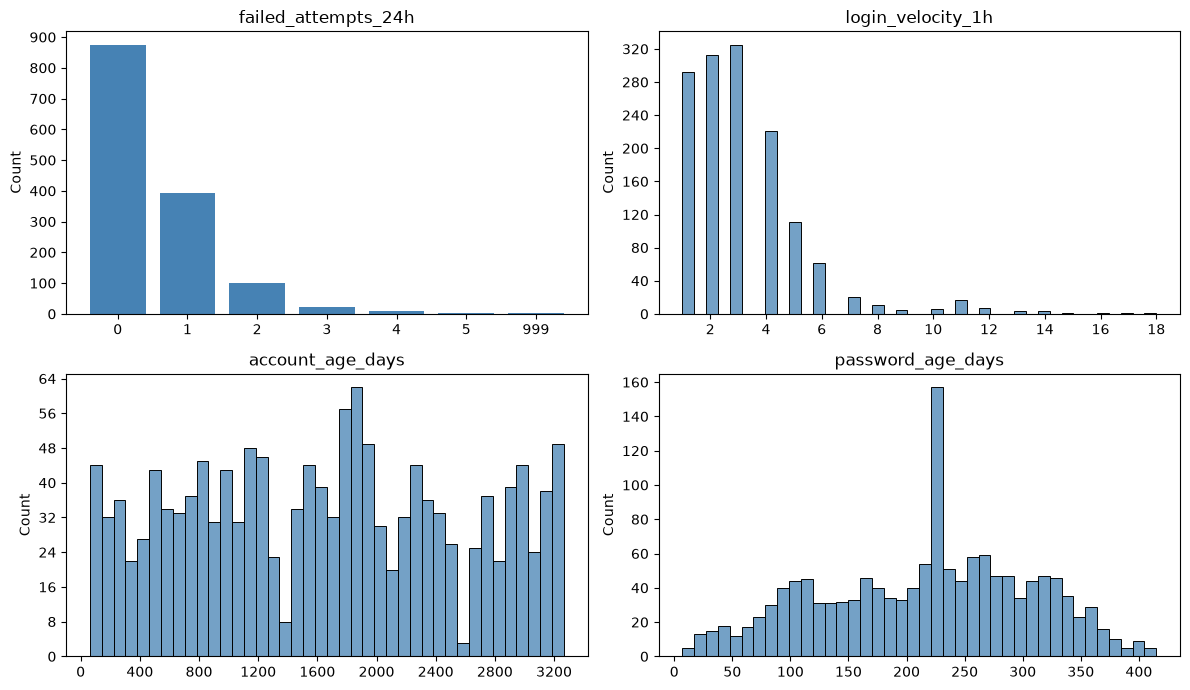

In [11]:
# ОТКРЫТЬ КОД
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

OUTLIER_COLS = ['failed_attempts_24h', 'login_velocity_1h',
                'account_age_days', 'password_age_days']

outl = df[OUTLIER_COLS].apply(pd.to_numeric, errors='coerce')

# IQR
rows, iqr_masks = [], {}
for col in OUTLIER_COLS:
    s = outl[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_mask = (outl[col] < low) | (outl[col] > high)
    iqr_masks[col] = iqr_mask
    rows.append({
        'признак': col,
        'нижняя граница IQR': round(low, 2),
        'верхняя граница IQR': round(high, 2),
        'выбросов по IQR': int(iqr_mask.sum()),
        'доля IQR, %': round(iqr_mask.mean() * 100, 2),
    })

outlier_summary = pd.DataFrame(rows).set_index('признак')
display(outlier_summary)

# гистограммы
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, OUTLIER_COLS):
    if col == 'failed_attempts_24h':
        counts = outl[col].dropna().astype(int).value_counts().sort_index()
        ax.bar(counts.index.astype(str), counts.values, color='steelblue')
    else:
        sns.histplot(outl[col].dropna(), bins=40, ax=ax, color='steelblue')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Count')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()
plt.close(fig)


Выбросы по межквартильному размаху обнаружены в двух из четырёх признаков:
- В признаке failed_attempts_24h верхняя граница равна 2.5, поэтому выбросами считаются значения от 3 и выше: таких строк 34, что составляет 2.43% от всех данных. Основная масса значений лежит в диапазоне от 0 до 2. 
- В признаке login_velocity_1h верхняя граница равна 7.0, то есть выбросами считается более 7 входов в час: таких строк 57 (4.07%).
- В признаках account_age_days и password_age_days выбросов не обнаружено, так как границы IQR вышли за пределы максимальных и минимальных значений признака.
  
Отрицательные нижние границы у всех признаков являются следствием формулы Q1 - 1.5·IQR и не имеют физического смысла для счётчиков и возраста.